# Housing Price Regression: Data Exploration, Preprocessing & Regularized Linear Models
**NTI Machine Learning Project**

## 1. Problem Understanding and Objective
This notebook investigates which property characteristics in the housing dataset are associated with selling prices and compares four linear modeling approaches—**Linear Regression**, **Ridge**, **Lasso**, and **Elastic Net**—alongside a `DummyRegressor` reference baseline.

**Workflow Roadmap:**
1. **Data Quality Audit & Exploration:** Inspect structure, data types, missing/duplicate entries, distributions, and feature relationships before applying transformations.
2. **Leak-Free Preprocessing:** Perform a fixed 80/20 train/test split (`random_state=42`) before fitting `StandardScaler` and `OneHotEncoder(drop="first")` inside a `ColumnTransformer`.
3. **Model Training & Hyperparameter Tuning:** Tune `alpha` and `l1_ratio` exclusively via 5-fold cross-validation on the training split.
4. **Fair Test Evaluation:** Compare all models on the single held-out test set using **MAE**, **RMSE**, and **$R^2$**.
5. **Residual & Coefficient Diagnostics + Experiments:** Inspect error patterns across price tiers, compare regularized vs. unregularized feature weights (framed strictly as statistical associations), and test targeted improvements (`log(price)` target transform, `RobustScaler`, and an `area × airconditioning` interaction).


In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)


## 2. Load the Dataset and Inspect Its Structure
The dataset file does not define the currency unit of `price`, the measurement unit of `area`, or the geographic criteria for `prefarea`. All analyses retain the raw dataset scales without assuming external definitions.


In [2]:
if os.path.exists("Housing.xlsx"):
    xls = pd.ExcelFile("Housing.xlsx")
    print("Excel sheets found:", xls.sheet_names)
    df = pd.read_excel(xls, sheet_name=xls.sheet_names[0])
elif os.path.exists("Housing.csv"):
    df = pd.read_csv("Housing.csv")
else:
    raise FileNotFoundError("Place Housing.xlsx or Housing.csv in the notebook directory.")

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())
print("\nColumn Data Types:")
print(df.dtypes)


Excel sheets found: ['Housing']
Dataset shape: 545 rows x 13 columns

Column Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## 3. Data Quality Audit
Before encoding or scaling, we verify:
- Missing values (`NaN`), blank/whitespace strings, and unique value counts per column.
- Exact duplicate records.
- Numerical ranges, median/IQR, and skewness.
- Category frequencies and class balance.


In [3]:
# 1. Missing values & whitespace check
audit_df = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "null_count": df.isnull().sum(),
    "whitespace_only": [df[c].astype(str).str.strip().eq("").sum() for c in df.columns],
    "n_unique": df.nunique()
})
display(audit_df)

# 2. Duplicate rows check
print(f"Exact duplicate rows: {df.duplicated().sum()}")

# 3. Numerical descriptive statistics
num_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]
num_summary = df[num_cols].describe().T
num_summary["median"] = df[num_cols].median()
num_summary["IQR"] = df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
num_summary["skewness"] = df[num_cols].skew()
display(num_summary.round(2))

# 4. Categorical value counts & percentages
cat_cols = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea", "furnishingstatus"
]
cat_rows = []
for col in cat_cols:
    vc = df[col].value_counts(dropna=False)
    for val, cnt in vc.items():
        cat_rows.append({
            "Feature": col,
            "Category": val,
            "Count": cnt,
            "Percentage (%)": round(cnt / len(df) * 100, 2),
            "Median Price": df.loc[df[col] == val, "price"].median()
        })
display(pd.DataFrame(cat_rows))


Exact duplicate rows: 0


,dtype,null_count,whitespace_only,n_unique
price,int64,0,0,219
area,int64,0,0,284
bedrooms,int64,0,0,6
bathrooms,int64,0,0,4
stories,int64,0,0,4
mainroad,object,0,0,2
guestroom,object,0,0,2
basement,object,0,0,2
hotwaterheating,object,0,0,2
airconditioning,object,0,0,2


,count,mean,std,min,25%,50%,75%,max,median,IQR,skewness
price,545.0,4766729.25,1870439.62,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0,4340000.0,2310000.0,1.21
area,545.0,5150.54,2170.14,1650.0,3600.0,4600.0,6360.0,16200.0,4600.0,2760.0,1.32
bedrooms,545.0,2.97,0.74,1.0,2.0,3.0,3.0,6.0,3.0,1.0,0.50
bathrooms,545.0,1.29,0.50,1.0,1.0,1.0,2.0,4.0,1.0,1.0,1.59
stories,545.0,1.81,0.87,1.0,1.0,2.0,2.0,4.0,2.0,1.0,1.08
parking,545.0,0.69,0.86,0.0,0.0,0.0,1.0,3.0,0.0,1.0,0.84


,Feature,Category,Count,Percentage (%),Median Price
0,mainroad,yes,468,85.87,4550000.0
1,mainroad,no,77,14.13,3290000.0
2,guestroom,no,448,82.20,4165000.0
3,guestroom,yes,97,17.80,5495000.0
4,basement,no,354,64.95,4077500.0
5,basement,yes,191,35.05,4900000.0
6,hotwaterheating,no,520,95.41,4329500.0
7,hotwaterheating,yes,25,4.59,5383000.0
8,airconditioning,no,373,68.44,3885000.0
9,airconditioning,yes,172,31.56,5757500.0


**Audit Takeaways:**
- The dataset contains **545 rows and 13 columns** with **zero missing values**, **zero whitespace-only strings**, and **zero exact duplicate rows**.
- All numerical features have plausible non-negative values (`area`: 1,650–16,200; `bedrooms`: 1–6; `bathrooms`: 1–4; `stories`: 1–4; `parking`: 0–3).
- `price` (skewness = `1.21`) and `area` (skewness = `1.32`) are moderately right-skewed.
- `hotwaterheating` is heavily imbalanced (`95.41%` `no` vs. `4.59%` `yes`, only 25 properties).


## 4. Exploratory Data Analysis and Insights
### 4.1 Price and Property Area Distributions


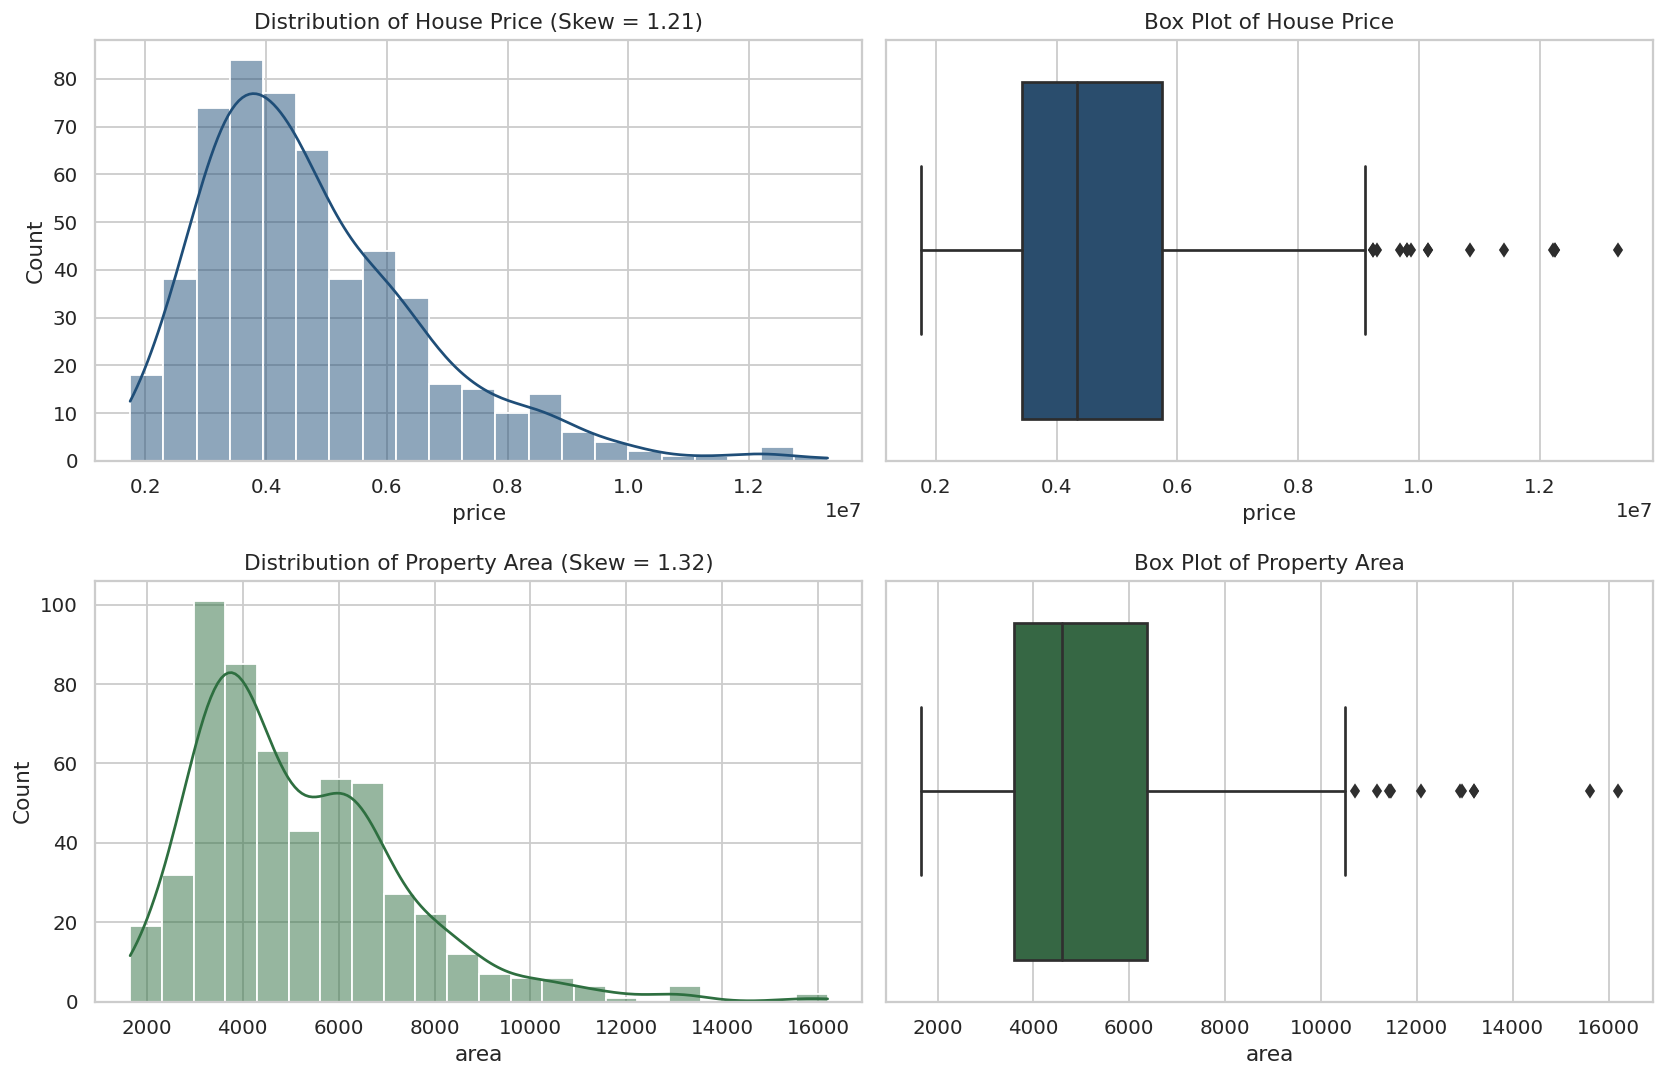

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

sns.histplot(df["price"], kde=True, ax=axes[0, 0], color="#1f4e78")
axes[0, 0].set_title("Distribution of House Price (Skew = 1.21)")

sns.boxplot(x=df["price"], ax=axes[0, 1], color="#1f4e78")
axes[0, 1].set_title("Box Plot of House Price")

sns.histplot(df["area"], kde=True, ax=axes[1, 0], color="#2e6f40")
axes[1, 0].set_title("Distribution of Property Area (Skew = 1.32)")

sns.boxplot(x=df["area"], ax=axes[1, 1], color="#2e6f40")
axes[1, 1].set_title("Box Plot of Property Area")

plt.tight_layout()
plt.show()


**Observation:** Both `price` (median `4,340,000`, IQR `2,310,000`) and `area` (median `4,600`, IQR `2,760`) exhibit right tails with legitimate high-end properties rather than data entry errors. We retain all 545 records and later test a `log1p(price)` transformation in Section 10.

### 4.2 Rooms, Stories, Parking & Price per Unit Area


Price per unit area summary:
count     545.00
mean      993.33
std       346.54
min       270.40
25%       745.37
50%       952.38
75%      1184.62
max      2640.00
dtype: float64
Correlation between area and price/area: -0.466


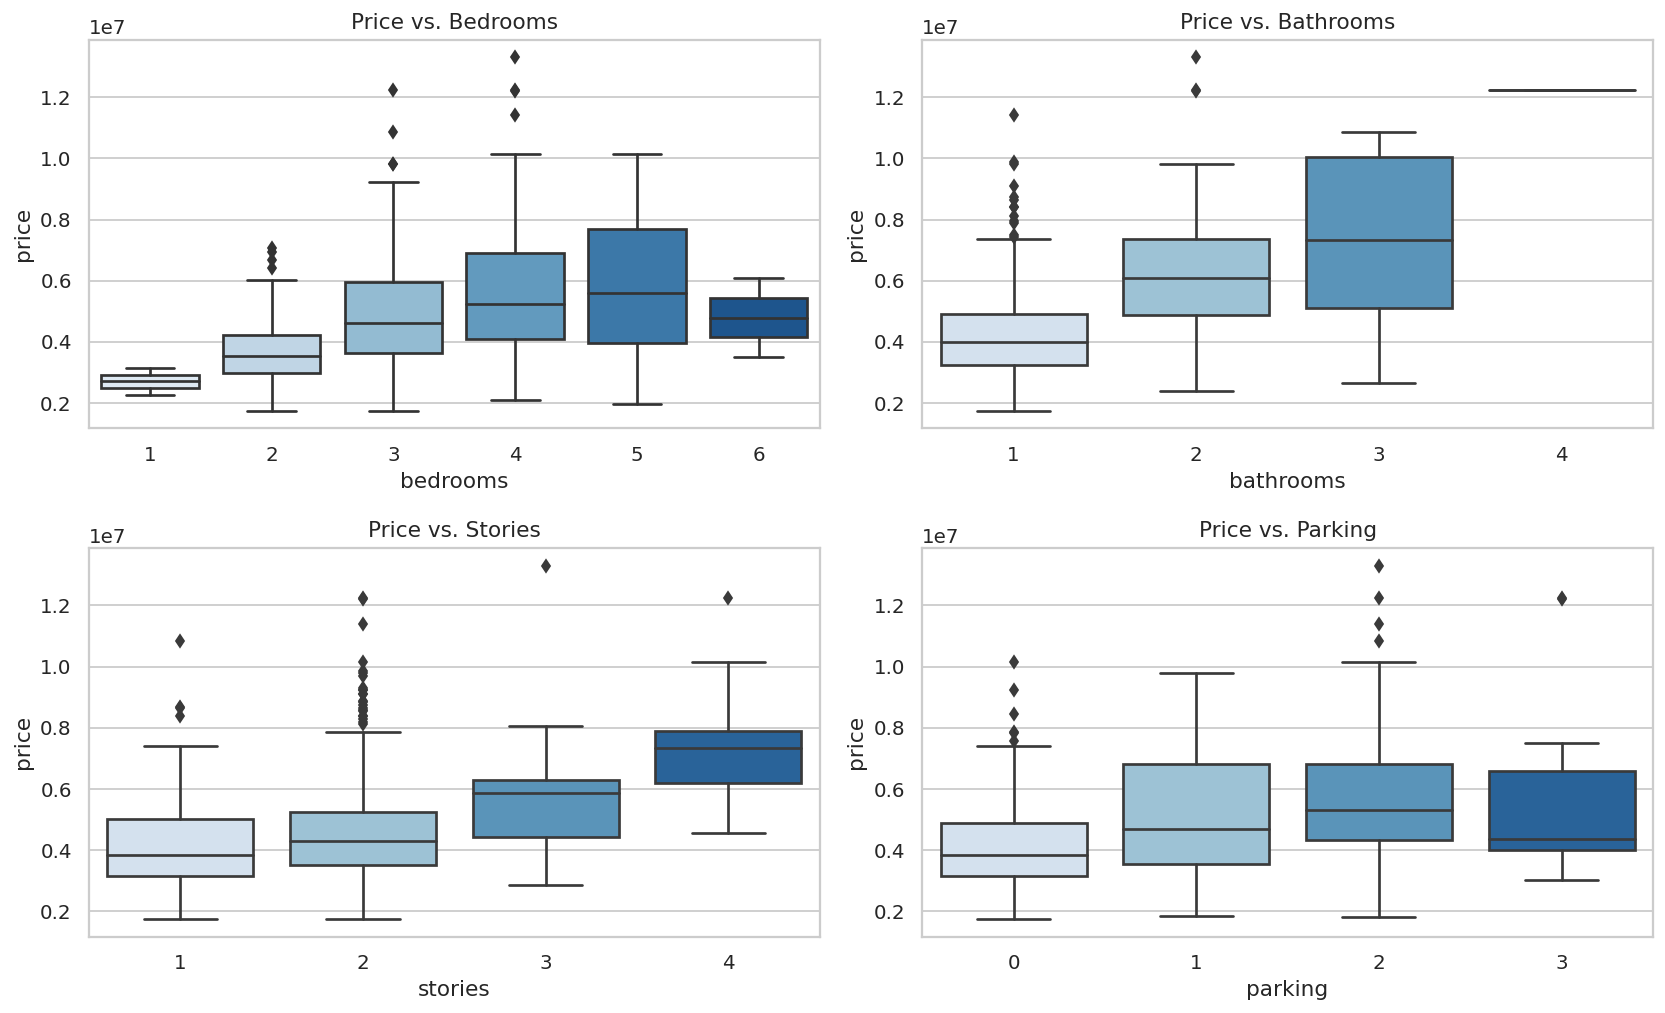

In [5]:
discrete_cols = ["bedrooms", "bathrooms", "stories", "parking"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, col in zip(axes.flat, discrete_cols):
    order = sorted(df[col].unique())
    sns.boxplot(data=df, x=col, y="price", order=order, ax=ax, palette="Blues")
    ax.set_title(f"Price vs. {col.capitalize()}")

plt.tight_layout()
plt.show()

# Investigate price per unit area
price_per_area = df["price"] / df["area"]
print("Price per unit area summary:")
print(price_per_area.describe().round(2))
print(f"Correlation between area and price/area: {df['area'].corr(price_per_area):.3f}")


**Observation:** Median `price` rises consistently with `bathrooms` (from `4,000,000` for 1 bathroom to `6,090,000` for 2 and `7,315,000` for 3) and `stories` (`3,850,000` for 1 story up to `7,350,000` for 4 stories). Meanwhile, `price / area` varies tenfold (`270.40` to `2,640.00`) and correlates negatively with `area` (`r = -0.466`), showing diminishing price per unit of lot area on very large parcels and highlighting that single-ratio metrics ignore vertical stories and interior amenities.

### 4.3 Area vs. Price Across Amenities and Furnishing Categories


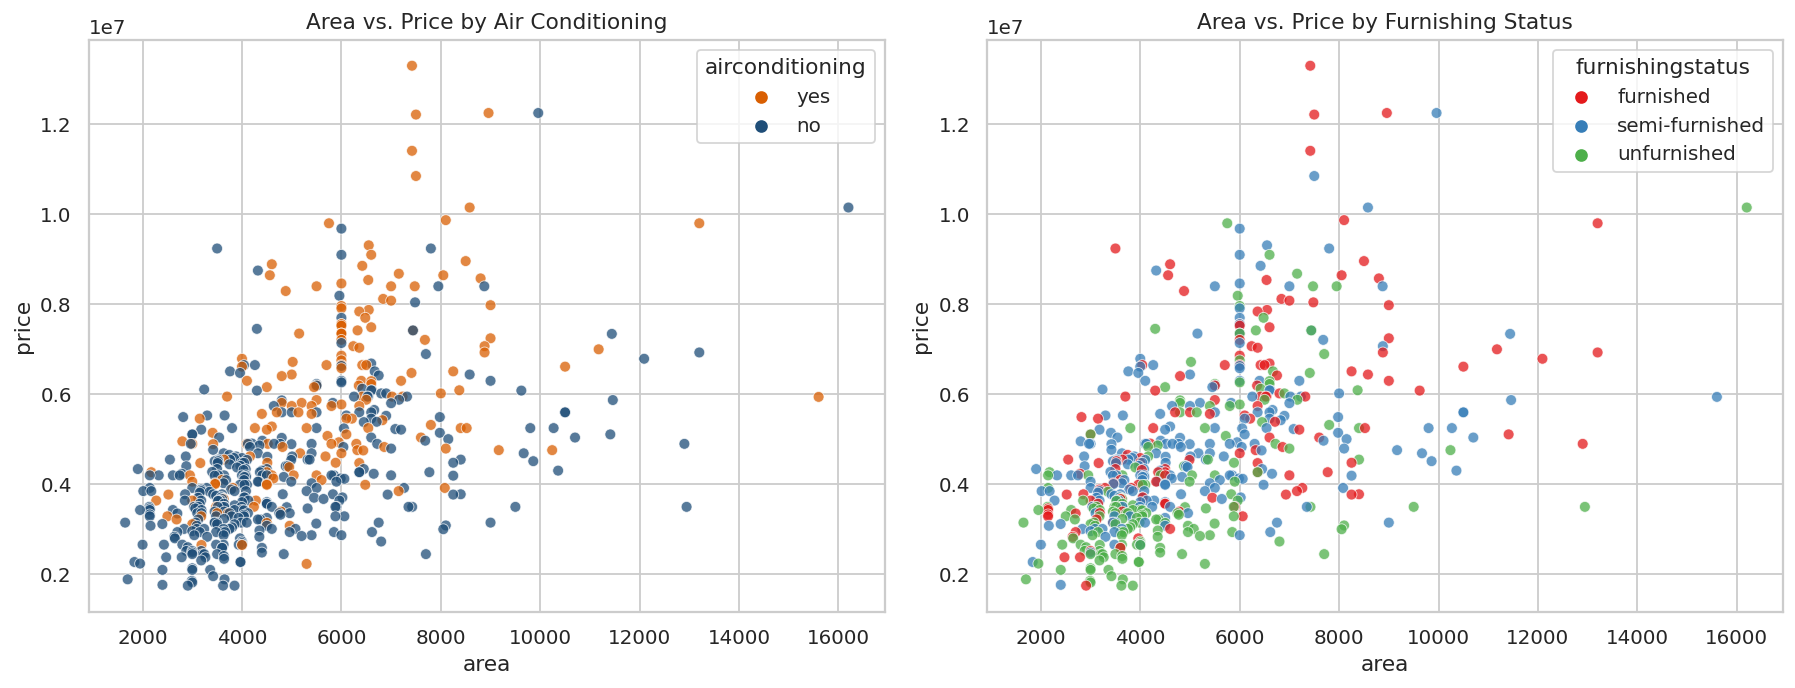

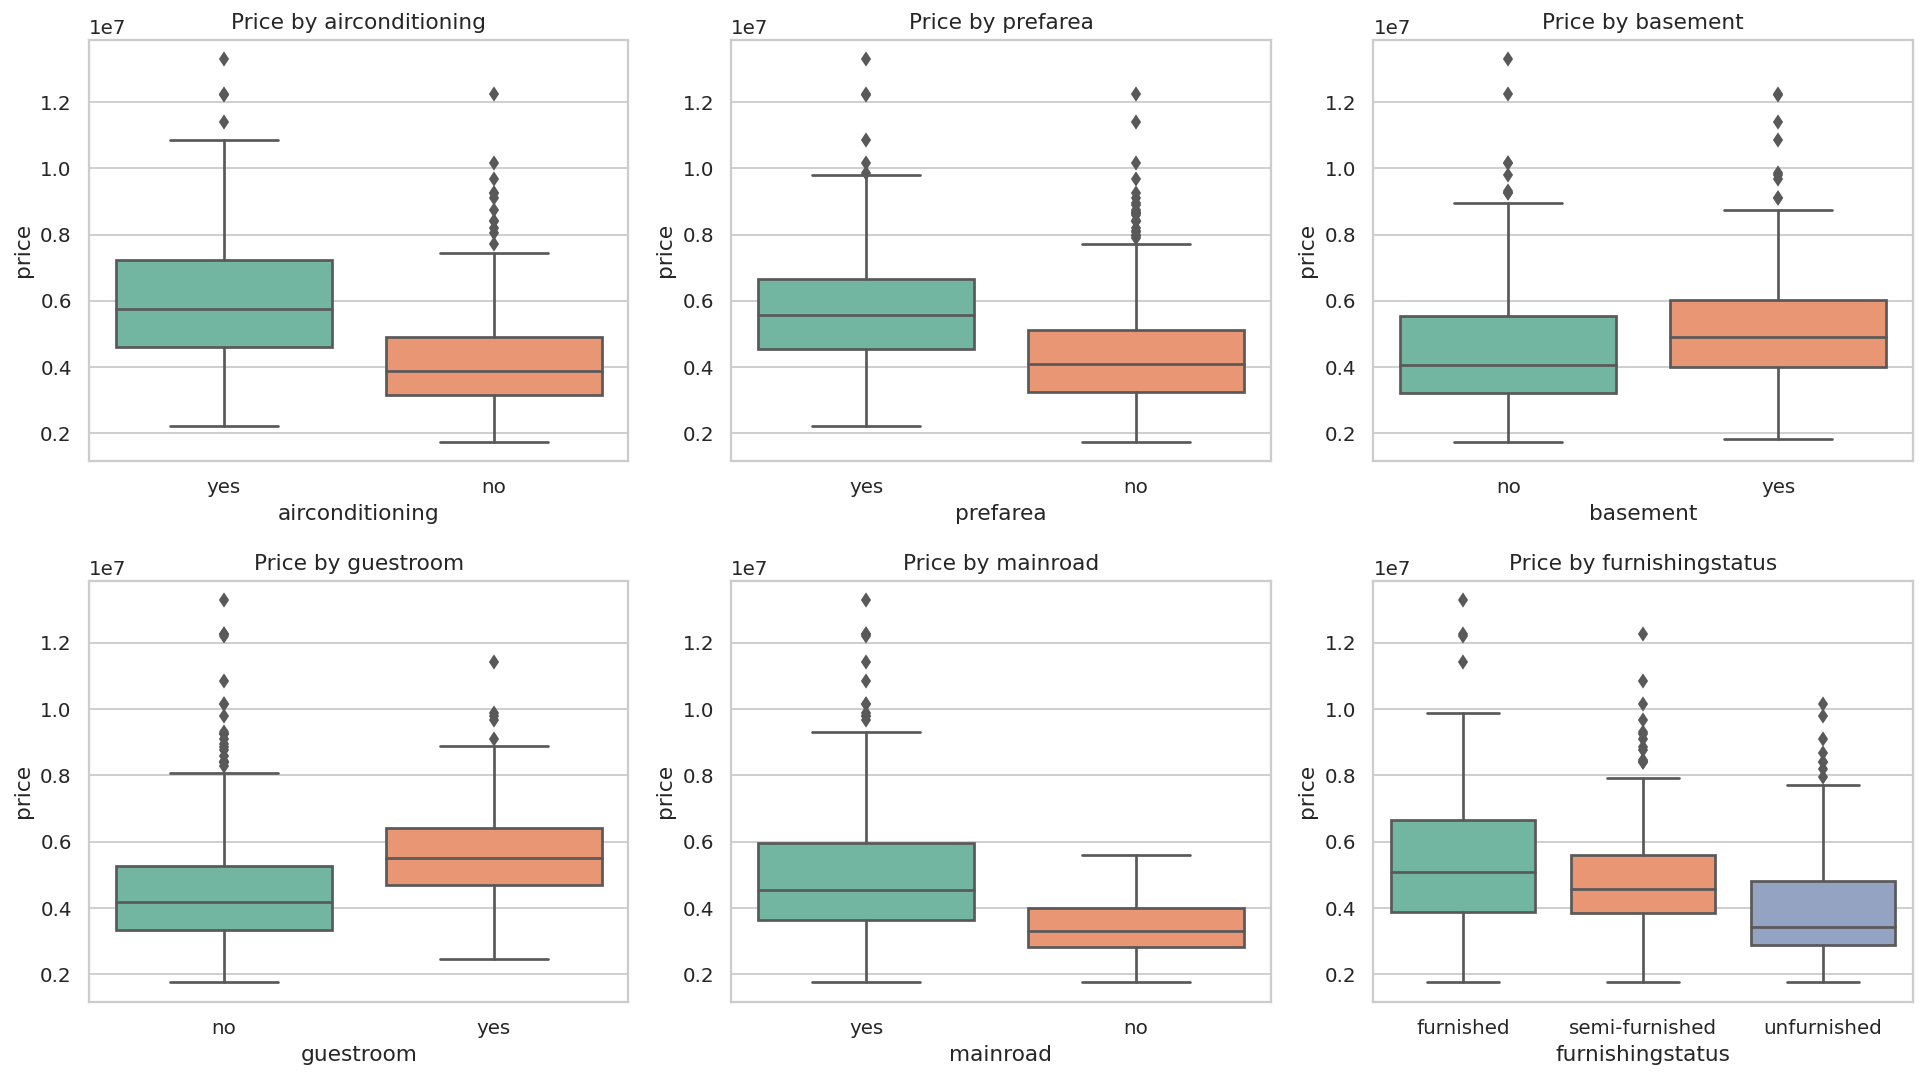

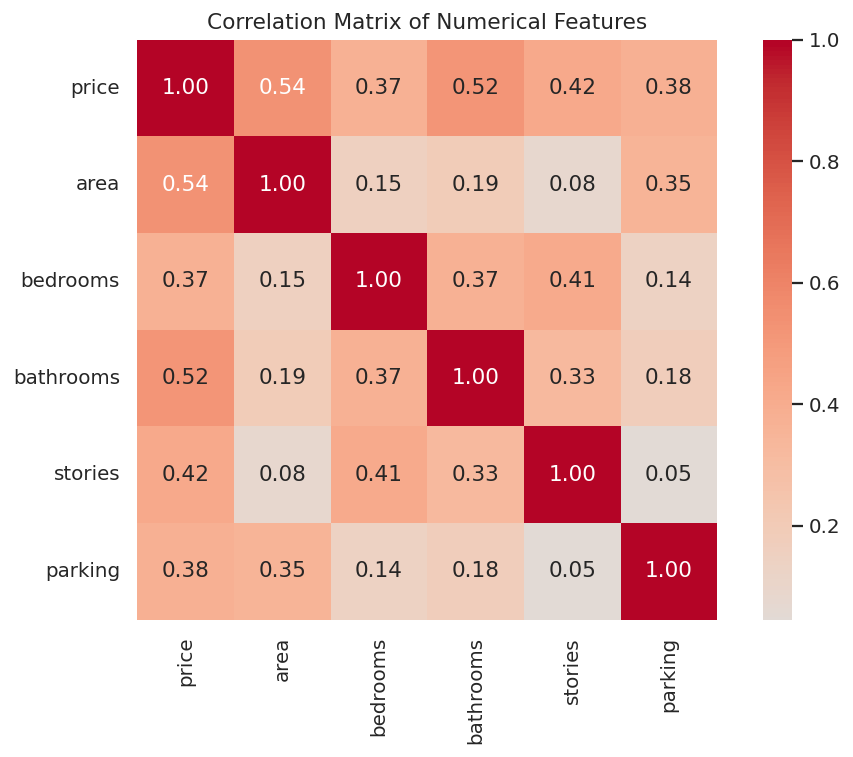

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.scatterplot(
    data=df, x="area", y="price", hue="airconditioning",
    alpha=0.75, ax=axes[0], palette={"yes": "#d95f02", "no": "#1f4e78"}
)
axes[0].set_title("Area vs. Price by Air Conditioning")

sns.scatterplot(
    data=df, x="area", y="price", hue="furnishingstatus",
    alpha=0.75, ax=axes[1], palette="Set1"
)
axes[1].set_title("Area vs. Price by Furnishing Status")

plt.tight_layout()
plt.show()

key_cats = ["airconditioning", "prefarea", "basement", "guestroom", "mainroad", "furnishingstatus"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))

for ax, col in zip(axes.flat, key_cats):
    sns.boxplot(data=df, x=col, y="price", ax=ax, palette="Set2")
    ax.set_title(f"Price by {col}")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


**Observation:**
- Across comparable `area` ranges, homes with `airconditioning = yes` (median `5,757,500` vs. `3,885,000`, `+48.2%`) and `prefarea = yes` (median `5,582,500` vs. `4,095,000`, `+36.3%`) sit noticeably higher in price.
- `furnishingstatus` shows unequal median gaps (`unfurnished`: `3,430,000`; `semi-furnished`: `4,585,000` [`+1,155,000`]; `furnished`: `5,075,000` [`+490,000`]), justifying one-hot encoding rather than assuming equal-interval numeric ranks.
- Pairwise numerical correlations among predictors are moderate (`max r = 0.41` between `bedrooms` and `stories`), indicating low severe multicollinearity.


## 5. Train/Test Split and Preprocessing Pipeline
To prevent data leakage:
1. Separate target `price` (`y`) from the 12 predictors (`X`).
2. Create a fixed **80/20 train/test split** (`436` train rows, `109` test rows, `random_state=42`) *before* fitting any transformers.
3. Wrap `StandardScaler()` (for the 5 numerical predictors) and `OneHotEncoder(drop="first")` (for the 7 categorical predictors, producing 8 binary indicator columns) inside a `ColumnTransformer`.


In [7]:
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} rows | Test set: {X_test.shape[0]} rows")
display(pd.DataFrame({
    "Train Price": y_train.describe(),
    "Test Price": y_test.describe()
}).round(2))

num_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]
cat_features = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea", "furnishingstatus"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_features),
    ]
)


Training set: 436 rows | Test set: 109 rows


,Train Price,Test Price
count,436.00,109.00
mean,4706527.39,5007536.70
std,1757976.29,2258621.66
min,1750000.00,1750000.00
25%,3498250.00,3290000.00
50%,4291000.00,4550000.00
75%,5600000.00,6510000.00
max,12250000.00,13300000.00


## 6. Reference Baselines: Dummy Regressor & Unregularized Linear Regression
We establish a constant-mean `DummyRegressor` benchmark and an unregularized `LinearRegression` baseline using the exact same 5-fold cross-validation (`KFold(n_splits=5, shuffle=True, random_state=42)`) and held-out test set.


In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_predictions(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

dummy_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", DummyRegressor(strategy="mean"))]),
    param_grid={},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

lr_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", LinearRegression())]),
    param_grid={},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

print(f"Dummy CV RMSE: {-dummy_grid.best_score_:,.2f} | Test: {evaluate_predictions(y_test, dummy_grid.best_estimator_.predict(X_test))}")
print(f"Linear Regression CV RMSE: {-lr_grid.best_score_:,.2f} | Test: {evaluate_predictions(y_test, lr_grid.best_estimator_.predict(X_test))}")


Dummy CV RMSE: 1,755,598.75 | Test: {'MAE': 1748624.606935443, 'RMSE': 2268298.228237694, 'R2': -0.017925679424830143}
Linear Regression CV RMSE: 1,023,579.38 | Test: {'MAE': 970043.403920164, 'RMSE': 1324506.9600914398, 'R2': 0.6529242642153178}


## 7. Regularized Models: Ridge, Lasso, and Elastic Net with Cross-Validation
Because `price` is measured in millions, regularization penalties operate on the scale of $X^T y$:
- **Ridge (`L2`):** `alpha` searched over `np.logspace(-2, 3, 60)` (`0.01` to `1,000`).
- **Lasso (`L1`):** `alpha` searched over `np.logspace(0, 5, 60)` (`1` to `100,000`) to cover soft-thresholding on million-scale targets.
- **Elastic Net (`L1 + L2`):** `alpha` over `np.logspace(-2, 3, 40)` and `l1_ratio` over `[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]`.


In [9]:
ridge_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Ridge(random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": np.logspace(-2, 3, 60)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

lasso_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", Lasso(max_iter=30000, random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": np.logspace(0, 5, 60)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

enet_grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", ElasticNet(max_iter=30000, random_state=RANDOM_STATE))]),
    param_grid={
        "model__alpha": np.logspace(-2, 3, 40),
        "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)

print(f"Best Ridge: alpha={ridge_grid.best_params_['model__alpha']:.4f} | CV RMSE={-ridge_grid.best_score_:,.2f}")
print(f"Best Lasso: alpha={lasso_grid.best_params_['model__alpha']:.2f} | CV RMSE={-lasso_grid.best_score_:,.2f}")
print(f"Best Elastic Net: alpha={enet_grid.best_params_['model__alpha']:.4f}, l1_ratio={enet_grid.best_params_['model__l1_ratio']} | CV RMSE={-enet_grid.best_score_:,.2f}")


Best Ridge: alpha=6.2605 | CV RMSE=1,021,858.48
Best Lasso: alpha=515.07 | CV RMSE=1,023,569.89
Best Elastic Net: alpha=0.0588, l1_ratio=0.7 | CV RMSE=1,021,859.19


## 8. Final Held-Out Test-Set Comparison


In [10]:
models = {
    "Dummy Regressor (Mean)": (dummy_grid.best_estimator_, -dummy_grid.best_score_, "strategy='mean'"),
    "Linear Regression": (lr_grid.best_estimator_, -lr_grid.best_score_, "Default (OLS)"),
    "Ridge Regression": (ridge_grid.best_estimator_, -ridge_grid.best_score_, f"alpha={ridge_grid.best_params_['model__alpha']:.4f}"),
    "Lasso Regression": (lasso_grid.best_estimator_, -lasso_grid.best_score_, f"alpha={lasso_grid.best_params_['model__alpha']:.2f}"),
    "Elastic Net": (enet_grid.best_estimator_, -enet_grid.best_score_, f"alpha={enet_grid.best_params_['model__alpha']:.4f}, l1_ratio={enet_grid.best_params_['model__l1_ratio']}"),
}

rows = []
for name, (est, cv_rmse, params) in models.items():
    m = evaluate_predictions(y_test, est.predict(X_test))
    rows.append({
        "Model": name,
        "Selected Hyperparameters": params,
        "5-Fold CV RMSE": cv_rmse,
        "Test MAE": m["MAE"],
        "Test RMSE": m["RMSE"],
        "Test R2": m["R2"]
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df.round({"5-Fold CV RMSE": 2, "Test MAE": 2, "Test RMSE": 2, "Test R2": 4}))


,Model,Selected Hyperparameters,5-Fold CV RMSE,Test MAE,Test RMSE,Test R2
0,Dummy Regressor (Mean),strategy='mean',1755598.75,1748624.61,2268298.23,-0.0179
1,Linear Regression,Default (OLS),1023579.38,970043.40,1324506.96,0.6529
2,Ridge Regression,alpha=6.2605,1021858.48,976710.08,1333742.45,0.6481
3,Lasso Regression,alpha=515.07,1023569.89,970367.83,1325112.58,0.6526
4,Elastic Net,"alpha=0.0588, l1_ratio=0.7",1021859.19,977820.70,1335657.14,0.6471


**Model Comparison Interpretation:**
- All four linear models dramatically outperform the constant-mean `DummyRegressor` (`Test R² = -0.0179`, `Test RMSE = 2,268,298`), explaining ~65% of test price variance.
- During 5-fold cross-validation, **Ridge (`alpha = 6.2605`)** achieves the lowest CV RMSE (`1,021,858`), edging out unregularized Linear Regression (`1,023,579`) by `0.17%`.
- On the held-out test set, all four models perform nearly identically (`Test R²` between `0.6471` and `0.6529`), with unregularized **Linear Regression** slightly ahead (`MAE = 970,043`, `RMSE = 1,324,507`, `R² = 0.6529`), followed closely by **Lasso** (`RMSE = 1,325,113`, `R² = 0.6526`). Because all 13 encoded features carry genuine predictive signal and multicollinearity is low, aggressive shrinkage or feature elimination does not yield large gains.


## 9. Residual and Coefficient Analysis
### 9.1 Residual Diagnostics & Subgroup Errors


Error Breakdown by Actual Price Tier:

Top 5 Largest Absolute Error Observations:


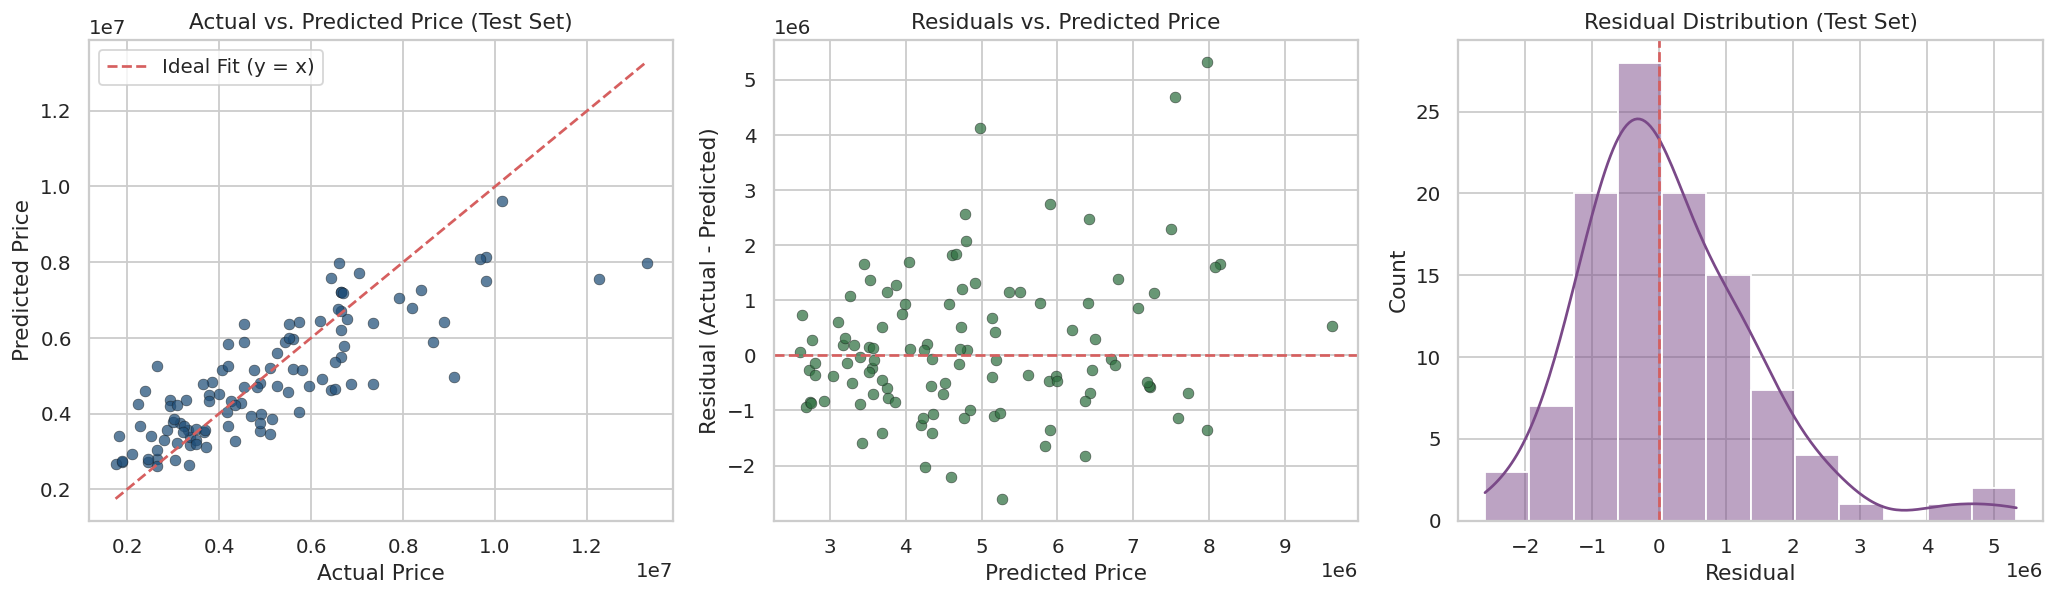

actual_price                    abs_error                      residual                  
                   mean     median count        mean      median count        mean      median count
price_tier                                                                                          
Low          2845216.22  2940000.0    37   753351.50   702362.10    37  -650939.38  -599338.70    37
Medium       4656458.33  4620000.0    36   691163.84   543167.20    36   -27999.44     9794.36    36
High         7581000.00  6702500.0    36  1471634.09  1151261.68    36  1139243.65  1139839.14    36

,actual_price,predicted_price,residual,area,bedrooms,bathrooms,stories,airconditioning,prefarea,furnishingstatus
0,13300000,7968276.13,5331723.87,7420,4,2,3,yes,yes,furnished
2,12250000,7555324.22,4694675.78,9960,3,2,2,no,yes,semi-furnished
15,9100000,4973331.10,4126668.90,6000,4,1,2,no,no,semi-furnished
22,8645000,5897888.53,2747111.47,8050,3,1,1,yes,no,furnished
499,2660000,5263187.75,-2603187.75,3630,3,3,2,no,no,unfurnished


In [11]:
y_pred_test = lr_grid.best_estimator_.predict(X_test)
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].scatter(y_test, y_pred_test, alpha=0.72, color="#1f4e78", edgecolors="k", linewidths=0.3)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Ideal Fit (y = x)")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Actual vs. Predicted Price (Test Set)")
axes[0].legend()

axes[1].scatter(y_pred_test, residuals, alpha=0.72, color="#2e6f40", edgecolors="k", linewidths=0.3)
axes[1].axhline(0, color="r", linestyle="--", lw=1.5)
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residuals vs. Predicted Price")

sns.histplot(residuals, kde=True, ax=axes[2], color="#7a4988")
axes[2].axvline(0, color="r", linestyle="--", lw=1.5)
axes[2].set_xlabel("Residual")
axes[2].set_title("Residual Distribution (Test Set)")

plt.tight_layout()
plt.show()

eval_df = X_test.copy()
eval_df["actual_price"] = y_test
eval_df["predicted_price"] = y_pred_test
eval_df["residual"] = residuals
eval_df["abs_error"] = residuals.abs()
eval_df["price_tier"] = pd.qcut(eval_df["actual_price"], q=3, labels=["Low", "Medium", "High"])

print("Error Breakdown by Actual Price Tier:")
display(eval_df.groupby("price_tier", observed=False)[["actual_price", "abs_error", "residual"]].agg(["mean", "median", "count"]).round(2))

print("\nTop 5 Largest Absolute Error Observations:")
display(eval_df.sort_values("abs_error", ascending=False)[
    ["actual_price", "predicted_price", "residual", "area", "bedrooms", "bathrooms", "stories", "airconditioning", "prefarea", "furnishingstatus"]
].head(5).round(2))


**Residual Findings:**
- **Heteroscedasticity & Upper-Tail Underprediction:** Errors are tightly centered in the middle tier (`mean residual = -27,999`, `MAE = 691,164`), slightly overpredicted in the low tier (`mean residual = -650,939`), and substantially underpredicted in the high tier (`mean residual = +1,139,244`, `MAE = 1,471,634`).
- **Extreme Error Cases:** The highest-priced home (`actual = 13,300,000`, `predicted = 7,968,276`, `residual = +5,331,724`) already has `airconditioning=yes`, `prefarea=yes`, `furnished`, 3 stories, and `area=7420`. An additive linear model cannot capture unobserved luxury attributes (architectural finish, micro-location, building age).

### 9.2 Coefficient Comparison Across Models


,Feature,Linear Regression,Ridge,Lasso,Elastic Net
9,airconditioning_yes,791426.74,732690.66,789355.28,721312.31
8,hotwaterheating_yes,684649.89,508871.08,672909.24,480178.06
10,prefarea_yes,629890.57,587949.74,628020.98,579461.39
2,bathrooms,521879.03,518004.33,521852.31,517055.28
0,area,519552.42,521955.67,520004.99,522299.17
12,furnishingstatus_unfurnished,-413645.06,-385702.26,-409246.64,-380019.15
7,basement_yes,390251.18,383940.37,389848.06,382114.96
5,mainroad_yes,367919.95,343629.14,364848.17,338782.45
3,stories,349251.44,353857.49,349531.44,354510.97
6,guestroom_yes,231610.04,231350.09,229375.68,231150.33


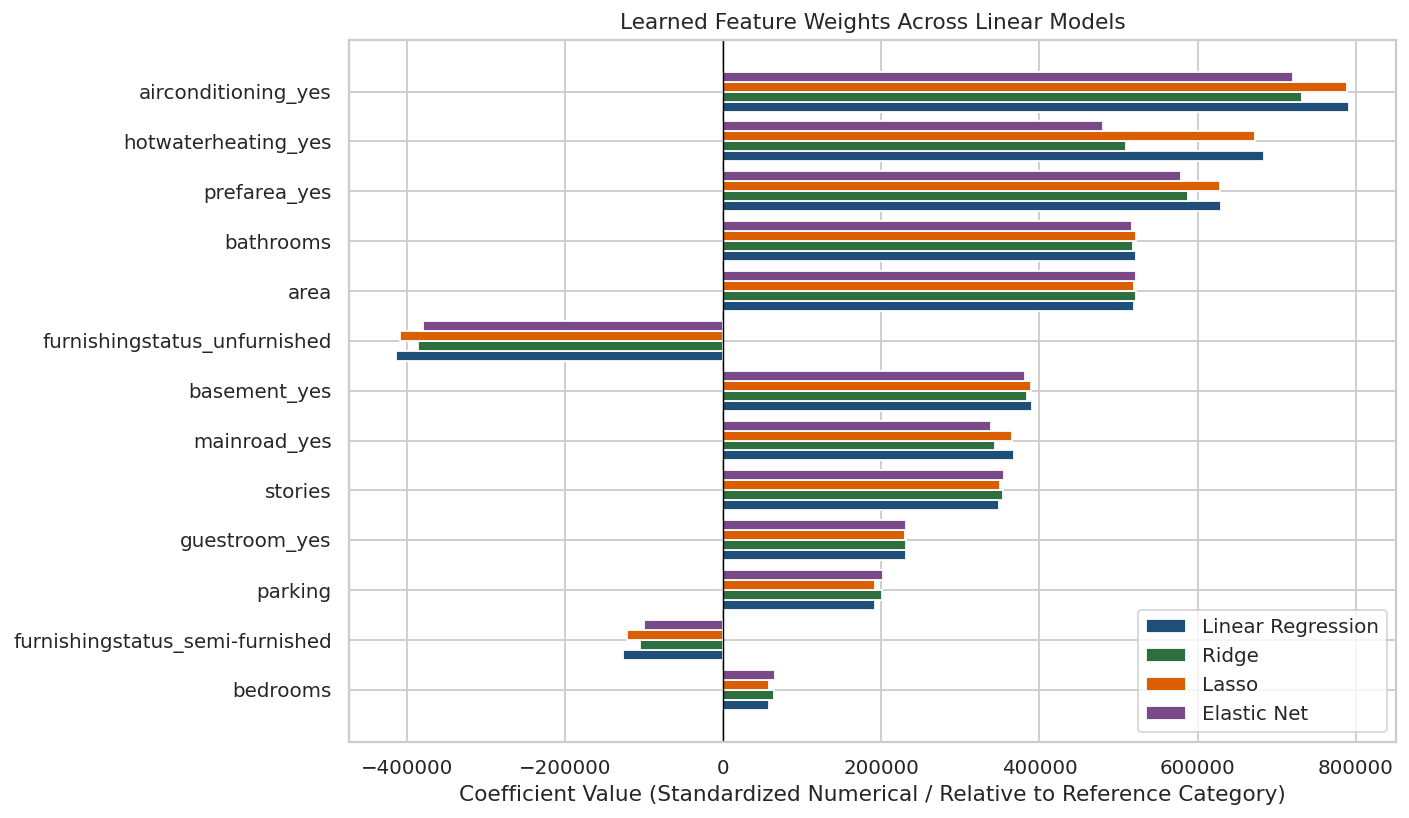

In [12]:
feat_names = [f.replace("num__", "").replace("cat__", "") for f in lr_grid.best_estimator_.named_steps["prep"].get_feature_names_out()]

coef_df = pd.DataFrame({
    "Feature": feat_names,
    "Linear Regression": lr_grid.best_estimator_.named_steps["model"].coef_,
    "Ridge": ridge_grid.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_grid.best_estimator_.named_steps["model"].coef_,
    "Elastic Net": enet_grid.best_estimator_.named_steps["model"].coef_,
}).sort_values(by="Linear Regression", key=abs, ascending=False)

display(coef_df.round(2))

plot_df = coef_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(plot_df))
h = 0.2
ax.barh(y_pos - 1.5*h, plot_df["Linear Regression"], height=h, label="Linear Regression", color="#1f4e78")
ax.barh(y_pos - 0.5*h, plot_df["Ridge"], height=h, label="Ridge", color="#2e6f40")
ax.barh(y_pos + 0.5*h, plot_df["Lasso"], height=h, label="Lasso", color="#d95f02")
ax.barh(y_pos + 1.5*h, plot_df["Elastic Net"], height=h, label="Elastic Net", color="#7a4988")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["Feature"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient Value (Standardized Numerical / Relative to Reference Category)")
ax.set_title("Learned Feature Weights Across Linear Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Coefficient Interpretation (Association, Not Causation):**
- Holding other predictors constant, `airconditioning_yes` (`+791,427` in OLS), `hotwaterheating_yes` (`+684,650`), and `prefarea_yes` (`+629,891`) are associated with the largest positive categorical shifts relative to their `no` baselines.
- Among standardized numerical features, a **one-standard-deviation increase** in `bathrooms` (`+0.50` bathrooms -> `+521,879` predicted price) and `area` (`+2,170` area units -> `+519,552` predicted price) carry the strongest positive associations, whereas `bedrooms` (`+57,350`) adds minimal incremental weight once `area` and `bathrooms` are controlled for.
- Ridge and Elastic Net shrink the rare `hotwaterheating_yes` weight (`4.59%` prevalence) most noticeably (`from 684,650 down to 508,871` and `480,178`), reducing variance on low-frequency indicators.


## 10. Controlled Additional Experiments
We test three targeted hypotheses on the exact same train/test split and CV folds:
1. **Log-Transformed Target (`log1p(price)`):** Addresses right skewness in `price` (`skew = 1.21`) and proportional price scaling; predictions are back-transformed via `expm1` before scoring.
2. **RobustScaler vs. StandardScaler:** Evaluates median/IQR scaling to reduce sensitivity to upper-tail `area` outliers.
3. **Interaction Term (`area × airconditioning`):** Tests whether larger properties command a steeper area slope when air-conditioned.


In [13]:
exp_rows = [{
    "Experiment": "Baseline: StandardScaler + OLS",
    "Modification": "Untransformed target, StandardScaler",
    "Best Params": "Default",
    "CV RMSE": -lr_grid.best_score_,
    "Test MAE": evaluate_predictions(y_test, lr_grid.best_estimator_.predict(X_test))["MAE"],
    "Test RMSE": evaluate_predictions(y_test, lr_grid.best_estimator_.predict(X_test))["RMSE"],
    "Test R2": evaluate_predictions(y_test, lr_grid.best_estimator_.predict(X_test))["R2"],
}]

# Exp 1: Log(price) + Ridge
log_ridge = GridSearchCV(
    Pipeline([
        ("prep", preprocessor),
        ("model", TransformedTargetRegressor(
            regressor=Ridge(random_state=RANDOM_STATE),
            func=np.log1p,
            inverse_func=np.expm1
        ))
    ]),
    param_grid={"model__regressor__alpha": np.logspace(-2, 3, 60)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)
m_log = evaluate_predictions(y_test, log_ridge.best_estimator_.predict(X_test))
exp_rows.append({
    "Experiment": "Exp 1: Log(price) Target + Ridge",
    "Modification": "TransformedTargetRegressor(log1p/expm1)",
    "Best Params": f"alpha={log_ridge.best_params_['model__regressor__alpha']:.4f}",
    "CV RMSE": -log_ridge.best_score_,
    "Test MAE": m_log["MAE"],
    "Test RMSE": m_log["RMSE"],
    "Test R2": m_log["R2"],
})

# Exp 2: RobustScaler + Ridge
rob_prep = ColumnTransformer([
    ("num", RobustScaler(), num_features),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_features),
])
rob_ridge = GridSearchCV(
    Pipeline([("prep", rob_prep), ("model", Ridge(random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": np.logspace(-2, 3, 60)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_train, y_train)
m_rob = evaluate_predictions(y_test, rob_ridge.best_estimator_.predict(X_test))
exp_rows.append({
    "Experiment": "Exp 2: RobustScaler + Ridge",
    "Modification": "Median/IQR scaling on numerical inputs",
    "Best Params": f"alpha={rob_ridge.best_params_['model__alpha']:.4f}",
    "CV RMSE": -rob_ridge.best_score_,
    "Test MAE": m_rob["MAE"],
    "Test RMSE": m_rob["RMSE"],
    "Test R2": m_rob["R2"],
})

# Exp 3: Area x AirConditioning Interaction + Ridge
X_tr_int = X_train.copy()
X_te_int = X_test.copy()
X_tr_int["area_x_ac"] = X_tr_int["area"] * (X_tr_int["airconditioning"] == "yes").astype(int)
X_te_int["area_x_ac"] = X_te_int["area"] * (X_te_int["airconditioning"] == "yes").astype(int)

int_prep = ColumnTransformer([
    ("num", StandardScaler(), num_features + ["area_x_ac"]),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_features),
])
int_ridge = GridSearchCV(
    Pipeline([("prep", int_prep), ("model", Ridge(random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": np.logspace(-2, 3, 60)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
).fit(X_tr_int, y_train)
m_int = evaluate_predictions(y_test, int_ridge.best_estimator_.predict(X_te_int))
exp_rows.append({
    "Experiment": "Exp 3: Area x AirConditioning + Ridge",
    "Modification": "Added area * airconditioning interaction",
    "Best Params": f"alpha={int_ridge.best_params_['model__alpha']:.4f}",
    "CV RMSE": -int_ridge.best_score_,
    "Test MAE": m_int["MAE"],
    "Test RMSE": m_int["RMSE"],
    "Test R2": m_int["R2"],
})

exp_df = pd.DataFrame(exp_rows)
display(exp_df.round({"CV RMSE": 2, "Test MAE": 2, "Test RMSE": 2, "Test R2": 4}))


,Experiment,Modification,Best Params,CV RMSE,Test MAE,Test RMSE,Test R2
0,Baseline: StandardScaler + OLS,"Untransformed target, StandardScaler",Default,1023579.38,970043.40,1324506.96,0.6529
1,Exp 1: Log(price) Target + Ridge,TransformedTargetRegressor(log1p/expm1),alpha=0.0100,1005443.36,960136.08,1314663.29,0.6581
2,Exp 2: RobustScaler + Ridge,Median/IQR scaling on numerical inputs,alpha=5.1507,1021836.38,970200.65,1329545.05,0.6503
3,Exp 3: Area x AirConditioning + Ridge,Added area * airconditioning interaction,alpha=7.6095,1019123.33,977153.90,1332992.61,0.6485


**Experiment Takeaways:**
- **Log-Target Transformation (`Exp 1`)** is the strongest overall improvement: modeling multiplicative price effects reduces **5-fold CV RMSE** from `1,023,579` to **`1,005,443`** and improves **Test MAE** (`960,136`), **Test RMSE** (`1,314,663`), and **Test $R^2$** (`0.6581`).
- **RobustScaler (`Exp 2`)** performs virtually identically to `StandardScaler` (`CV RMSE = 1,021,836`), showing that upper-tail `area` values do not distort standard variance scaling.
- **Area × Air Conditioning (`Exp 3`)** slightly lowers CV RMSE (`1,019,123`) during training, but slightly increases test error (`Test RMSE = 1,332,993`), indicating mild overfitting on the small 109-row test split.

## 11. Limitations and Conclusion
1. **Unobserved Property Attributes:** Structural variables explain ~65–66% of price variance; the remaining ~34% reflects missing variables such as micro-location, property age, construction quality, interior finishes, and sale date.
2. **Unspecified Dataset Units:** Currency, area unit, and `prefarea` criteria are absent from the source file, preventing external market benchmarking.
3. **Sample Size Constraints:** With 545 observations, linear models generalize more reliably than high-degree interaction models, particularly in the sparse luxury tail (`price > 9,000,000`).
4. **Recommendation:** For interpretable baseline valuation on this dataset, use **Ridge or Linear Regression with a `log1p(price)` target transformation**, and flag high-value properties (`predicted price > 7,000,000`) for manual appraisal where additive linear assumptions underpredict.
